# Where does each town stop coping under *sustained* demand?

`carla-demand-sweep.ipynb` raised the arrival rate while holding the request
count at 30, so a faster rung meant the same 30 riders arriving in a shorter
burst. That sweep found no breaking point anywhere on its ladder, and the
reason is visible in its own numbers: **fixed route got *better* as the rate
rose** (TAU 47.8% -> 71.1%, Town05 43.3% -> 61.1%). Nothing should improve
under load. Three things moved together when the interval shortened — total
simulated time fell, distance driven fell, and the pending pool filled up
earlier — so the sweep varied burst concentration and lookahead, not the
demand the bus has to keep up with. Its seat occupancy peaked at 36% of 20.

This notebook asks the question the other one could not.

## The change: pin the span, scale the volume

**The arrival span is fixed at 2700 s and `max_requests` scales with the
rate.** Every rung offers demand for the same 45 minutes; what changes is how
many riders arrive in it. That is what "sustained" means — the bus never gets
a quiet tail to catch up in until the span is over.

| interval | 90 s | 45 s | 30 s |
|---|---|---|---|
| offered | 0.67/min | 1.33/min | 2.00/min |
| requests | 30 | 60 | 90 |
| arrival span | 2700 s | 2700 s | 2700 s |

The 90 s rung is the campaign's own operating point *and* the burst sweep's
slowest rung — 30 requests over 2700 s is the same trial under either
reading. So it costs nothing, and section 7 uses it as a shared anchor the
two experiments must agree on exactly.

## Capacity is now a second moving variable, on purpose

By Little's law the mean number aboard is `arrival rate x ride time`. At a
ride time of roughly 500 s the ladder gives about 28%, 55% and 83% of the 20
seats. The burst sweep could not move that number; this one takes it across
the **~60% occupancy threshold** at which the synthetic map's ranking
inverts and fixed route starts winning
(see `synthetic-load-crossover-capacity-20.ipynb`).

That makes this two experiments in one, and section 6 is the reason to run
it: nothing in the project has yet tested the occupancy inversion on real
geometry. Section 4 measures occupancy directly rather than assuming the
estimate above, so if the ladder lands somewhere else that is visible rather
than silent.

!!! warning "What is deliberately not separated"
    Rate and volume move together by construction, so a rung that fails
    cannot be attributed to *only* one of them. That is the definition of
    sustained load and not a confound to fix — but it does mean "Town05
    breaks at 1.33/min" is a statement about an operating point, not about
    an arrival rate in isolation.

## Sized to be run in an evening

**36 new trials, roughly 2.6 h**, against the burst sweep's 180. Three towns
rather than five (Town02 is inert — 92–100% for every policy at every rung;
Town01 duplicates Town03's profile at the same cost), two policies rather
than three (Window tracked Reordering inside the seed noise in all five
towns), three rungs rather than five.

Seeds stay at 3, which is the one axis not cut. The burst sweep's headline
failures were all a single seed — seed 2 is the worst draw in every town —
and cutting to 2 would make every cell here unreadable for the same reason.
Three is still few: **read section 5 with the per-seed spread beside it, not
the means alone.**

## Running it

Needs a live server: `docker compose up -d`, then a minute. Sequential —
`CarlaBackend` sets `parallel_safe = False`. Everything lands in the shared
results store, so an interrupted run resumes.

## Configuration

In [1]:
# --- Towns ---------------------------------------------------------------
# Three of the campaign's five. TAU is the project's own map and the
# cheapest to run; Town05 is the hardest and the only town where Reordering
# missed the 80% gate in the burst sweep; Town03 sits between them.
ALL_TOWNS = ["TAU", "Town03", "Town05"]

# --- Held identical to the campaign and the burst sweep ------------------
# Every one of these matches carla-campaign-towns.ipynb and
# carla-demand-sweep.ipynb exactly -- except CAPACITY, which is halved and
# is the entire point of this copy. Capacity is part of a run's identity,
# so that one difference means nothing here is reused from either of them:
# the 90 s rung is re-driven at 12 seats rather than borrowed, and the
# capacity-20 sweep stands beside this one as the comparison. Change any
# of the others and the two stop being comparable at all.
NPC_VEHICLES = 20
# Halved from 20 to push seat occupancy past the ~60% above which the
# synthetic map says the ranking inverts. Section 4 reports what was
# actually reached, which is the number this sweep turns on.
CAPACITY = 12
WINDOW = 750.0
PATIENCE = 750.0
DWELL_S = 10.0
FIXED_DELTA_S = 0.05
MAX_TIME = 40000.0

# --- The sustained-load design -------------------------------------------
# The span is what is held fixed here, and max_requests is derived from it.
# In the burst sweep it was the other way round: max_requests was pinned at
# 30 and the span shrank with the interval, which is precisely why that
# sweep's fast rungs were shorter and easier rather than harder.
ARRIVAL_SPAN_S = 2700.0
DEMAND_INTERVALS = [90.0, 45.0, 30.0]

# The rung both experiments share: 30 requests at 90 s IS 2700 s of span.
ANCHOR_INTERVAL = 90.0

# --- Sample size ---------------------------------------------------------
# Three seeds a rung, same subset the burst sweep used, so the anchor rung
# is already covered for every one of them. Not a significance test.
SEEDS = list(range(3))

# --- Cost ----------------------------------------------------------------
# Measured per-trial wall minutes at the anchor, averaged over the stored
# campaign runs. ETA only.
MEASURED_TRIAL_MINUTES = {"Town01": 5.20, "Town02": 4.29, "Town03": 5.27,
                          "Town05": 6.11, "TAU": 1.69}
DEFAULT_TRIAL_MINUTES = 5.0

# Wall time tracks simulated time, which is the arrival span plus a tail
# spent finishing the riders still in flight when demand stops. The tail is
# bounded by patience -- an unserved rider abandons after 750 s rather than
# queueing -- so it does not grow without limit as the rungs get busier.
#
# Because the span is now FIXED, every rung costs about the same, which is
# the incidental benefit of this design over the burst sweep's.
SETTLING_TAIL_S = 900.0
ANCHOR_SIM_S = ARRIVAL_SPAN_S + SETTLING_TAIL_S

CARLA_HOST, CARLA_PORT = "localhost", 2000

In [2]:
def requests_for(interval_s: float) -> int:
    """
    How many requests fill the fixed arrival span at a given rate.

    This is the whole design of the notebook in one line: the span is the
    constant and the volume is derived, so a faster rung is a busier 45
    minutes rather than a shorter one.

    :param interval_s: Demand interval in seconds.
    :return: Requests to emit, rounded to a whole rider.
    """
    return round(ARRIVAL_SPAN_S / interval_s)


# Every rung's request count, resolved once so the runner, the store filter
# and the tables cannot disagree about what a rung is.
RUNG_REQUESTS = {i: requests_for(i) for i in DEMAND_INTERVALS}


def expected_minutes(town: str) -> float:
    """
    Estimated wall minutes for one trial.

    Independent of the rung: the measured figure was taken at a run whose
    simulated time was ANCHOR_SIM_S, and every rung here has that same
    simulated length because the span is fixed. Planning cost does grow with
    the pending pool, which this ignores; the progress bar's rolling mean
    absorbs that within five trials.

    :param town: Town the trial runs in.
    :return: Minutes, for the progress bar only.
    """
    return MEASURED_TRIAL_MINUTES.get(town, DEFAULT_TRIAL_MINUTES)


print(f"arrival span held at {ARRIVAL_SPAN_S:.0f} s for every rung\n")
for interval in DEMAND_INTERVALS:
    count = RUNG_REQUESTS[interval]
    print(f"  {60 / interval:>4.2f}/min  ->  {count:>3} requests"
          f"  (interval {interval:.0f} s)"
          + ("   [already in the store]"
             if interval == ANCHOR_INTERVAL else ""))

cells_total = len(ALL_TOWNS) * 2 * len(SEEDS) * len(DEMAND_INTERVALS)
new_trials = len(ALL_TOWNS) * 2 * len(SEEDS) * (len(DEMAND_INTERVALS) - 1)
print(f"\n{len(ALL_TOWNS)} towns x 2 policies x {len(SEEDS)} seeds x "
      f"{len(DEMAND_INTERVALS)} rungs = {cells_total} trials, "
      f"of which {new_trials} are new")

budget = sum(expected_minutes(t) * 2 * len(SEEDS)
             * (len(DEMAND_INTERVALS) - 1) for t in ALL_TOWNS)
print(f"estimated new work: {budget / 60:.1f} h")

arrival span held at 2700 s for every rung

  0.67/min  ->   30 requests  (interval 90 s)   [already in the store]
  1.33/min  ->   60 requests  (interval 45 s)
  2.00/min  ->   90 requests  (interval 30 s)

3 towns x 2 policies x 3 seeds x 3 rungs = 54 trials, of which 36 are new
estimated new work: 2.6 h


In [3]:
import statistics
import time

import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler
from tqdm.auto import tqdm

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.experiment import run_campaign
from src.experiment.store import DEFAULT_RUNS_DIR, load_runs
from src.map.carla_stops import stops_path
from src.map.carla_topology import topology_path
from src.map.CarlaMapProvider import CarlaMapProvider
from src.simulation.CarlaBackend import (
    CarlaBackend, speed_limits_from, stop_positions_from,
)
from src.simulation.carla_world import (
    GENERATED_SPEED_CEILING_KPH, is_generated,
)

from IPython.display import Markdown, display

# The campaign's palette, so the three notebooks' charts are read together.
# Fixed route keeps slot 0 and Reordering slot 2, as in the burst sweep --
# Window's orange is simply left unused rather than reassigned.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

POLICY_COLOUR = {"Fixed route": SERIES[0], "Reordering W750": SERIES[2]}
POLICY_LABELS = ["Fixed route", "Reordering W750"]
POLICIES = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Reordering W750",
     lambda g: ReorderingInsertionPolicy(g, max_wait_s=WINDOW)),
]

# max_requests is deliberately absent alongside demand_interval_s: both are
# swept and both are supplied per rung. Everything that remains matches the
# burst sweep's BASE_TRIAL field for field, which is what lets the anchor
# rung's stored runs be reused rather than re-simulated.
BASE_TRIAL = dict(
    capacity=CAPACITY, max_wait_s=PATIENCE, dwell_s=DWELL_S,
    max_time=MAX_TIME,
)

# The 80% fulfilment gate from the design review's SS3.2.2.
GATE = 80.0

# The occupancy at which the synthetic map's ranking inverts. Drawn as a
# reference line in section 6, not assumed anywhere in the analysis.
INVERSION_OCCUPANCY = 60.0

## 1. Are the towns still prepared?  *(no server needed)*

Cheap, and it fails loudly rather than letting the sweep skip a town and
report two. A `traffic_efficiency` of 1.0 means uncalibrated: run
`carla-campaign-towns.ipynb` section 3 first.

In [4]:
def speed_limit_tag(town: str) -> str:
    """
    How this town's speed limits were derived, for the run identity.

    A shipped town publishes type-274 landmarks; a generated one has none,
    so its limits come from the .xodr's per-lane elements and are capped.
    The two are different procedures and must not pool -- which is also why
    this is a function rather than a literal: hardcoding the shipped town's
    tag in a filter silently drops every generated town's runs.

    :param town: Town name.
    :return: The identity tag for that town's speed-limit source.
    """
    if is_generated(town):
        return f"xodr-capped-{int(GENERATED_SPEED_CEILING_KPH)}-v1"
    return "landmark-harmonic-v1"


def readiness(town: str) -> dict:
    """
    Report whether one town can be swept.

    :param town: Town name.
    :return: A row describing what is present and what is not.
    """
    has_topology = topology_path(town).exists()
    has_stops = stops_path(town).exists()
    efficiency, stops, note = None, None, ""
    if has_topology and has_stops:
        try:
            provider = CarlaMapProvider(town)
            efficiency = provider.traffic_efficiency()
            stops = len(provider.get_stops())
            problems = provider.validate()
            note = "OK" if not problems else f"{len(problems)} map problems"
        except Exception as error:              # noqa: BLE001
            note = f"failed to load: {error!r}"
    return {
        "town": town,
        "topology": "yes" if has_topology else "MISSING",
        "stops": stops if stops is not None else (
            "yes" if has_stops else "MISSING"),
        "traffic_efficiency": efficiency if efficiency is not None else "-",
        "speed_limits": speed_limit_tag(town),
        "ready": "yes" if efficiency not in (None, 1.0) else "no",
        "note": note,
    }


display(pd.DataFrame([readiness(t) for t in ALL_TOWNS]).set_index("town"))

READY_TOWNS = [
    t for t in ALL_TOWNS
    if stops_path(t).exists() and topology_path(t).exists()
    and CarlaMapProvider(t).traffic_efficiency() != 1.0
]
print(f"ready to sweep: {READY_TOWNS}")
missing = [t for t in ALL_TOWNS if t not in READY_TOWNS]
if missing:
    display(Markdown(
        f"> **Not sweeping: {', '.join(missing)}.** Uncalibrated or missing "
        "an artifact -- prepare it in `carla-campaign-towns.ipynb` "
        "sections 2-3 first."))

,topology,stops,traffic_efficiency,speed_limits,ready,note
town,,,,,,
TAU,yes,25,0.6994,xodr-capped-50-v1,yes,34 map problems
Town03,yes,15,0.6274,landmark-harmonic-v1,yes,3 map problems
Town05,yes,15,0.3671,landmark-harmonic-v1,yes,OK


ready to sweep: ['TAU', 'Town03', 'Town05']


## 2. Run the sweep  🖥 *needs a live server*

Rung-major within a town, and one `run_campaign` call per trial so a CARLA
hiccup costs one trial rather than the night. Anything already recorded is
skipped, so the anchor rung comes back instantly and re-running after an
interruption resumes.

Three nested bars — towns, then rungs, then trials — with a rolling mean over
the last five trials. Unlike the burst sweep the rungs cost about the same,
so a drifting rolling mean here means planning cost growing with the pending
pool, which is itself worth noticing.

In [5]:
def world_for(town: str, provider: CarlaMapProvider) -> dict:
    """
    Build the store identity for one town's world.

    Identical to the campaign's and the burst sweep's, field for field,
    which is what lets the anchor rung reuse its runs. Every tag in here
    changes what the bus does, and omitting one would let two different
    buses share an identity.

    :param town: Town name.
    :param provider: That town's loaded provider.
    :return: The world identity.
    """
    return {
        "town": town, "backend": "CarlaBackend",
        "npc_vehicles": NPC_VEHICLES, "fixed_delta_s": FIXED_DELTA_S,
        "no_rendering": True, "blueprint": "vehicle.volkswagen.t2_2021",
        "traffic_efficiency": provider.traffic_efficiency(),
        "speed_limits": speed_limit_tag(town),
        # v2 (2026-08-24): the bus's lateral PID gain went 1.95 ->
        # 0.75 and its steering ceiling 0.8 -> 0.45, to stop it
        # slamming to full lock in junctions. That changes leg times,
        # so v1 and v2 runs must not pool.
        "steering": "direct-drive-v2",
        "routing": "time-lane-change-v1",
    }


def backend_factory_for(town: str, positions: dict, speed_for):
    """
    Build a per-seed world builder for one town.

    :param town: Town to drive in.
    :param positions: That town's stop coordinates.
    :param speed_for: That town's speed-limit lookup, so the planner prices
        legs in travel time exactly as TransitGraph does.
    :return: A function of seed returning a backend factory.
    """
    def for_seed(seed: int):
        def build(graph, start_stop_id: str) -> CarlaBackend:
            """Build the CARLA backend for one trial."""
            return CarlaBackend(
                stop_positions=positions, position=start_stop_id, town=town,
                speed_for=speed_for, lane_changes=True,
                host=CARLA_HOST, port=CARLA_PORT,
                fixed_delta_s=FIXED_DELTA_S, dwell_s=DWELL_S,
                npc_vehicles=NPC_VEHICLES, seed=seed, no_rendering=True,
                # CARLA results are not independent of server history: an
                # earlier campaign lost 7 Town05 runs to a back-to-back
                # trials artefact and had to be discarded.
                reload_world=True)
        return build
    return for_seed


RUN_SWEEP = True    # set False to skip; needs a live server

if RUN_SWEEP and not READY_TOWNS:
    display(Markdown("> **Nothing to run.** No town is prepared."))

if RUN_SWEEP and READY_TOWNS:
    failures, durations = [], []
    towns_bar = tqdm(READY_TOWNS, desc="towns", unit="town")
    for town in towns_bar:
        towns_bar.set_postfix_str(town)
        provider = CarlaMapProvider(town)
        positions = stop_positions_from(provider)
        world = world_for(town, provider)
        for_seed = backend_factory_for(
            town, positions, speed_limits_from(provider))
        expected = expected_minutes(town)

        rungs_bar = tqdm(DEMAND_INTERVALS, desc=f"  {town}", unit="rung",
                         leave=False)
        for interval in rungs_bar:
            count = RUNG_REQUESTS[interval]
            rungs_bar.set_postfix_str(
                f"{60 / interval:.2f}/min, {count} requests")
            trials_bar = tqdm(
                total=len(SEEDS) * len(POLICIES), unit="trial", leave=False,
                desc=f"    {60 / interval:.2f}/min")
            # Seed-major so both policies of a seed finish together: an
            # interrupted run then leaves paired data rather than an orphan.
            for seed in SEEDS:
                for label, factory in POLICIES:
                    started = time.perf_counter()
                    ran = 0
                    try:
                        outcome = run_campaign(
                            policies=[(label, factory)], seeds=[seed],
                            world=world, directory=DEFAULT_RUNS_DIR,
                            provider=provider, backend_factory_for=for_seed,
                            n_jobs=1, progress=False,
                            demand_interval_s=interval,
                            max_requests=count, **BASE_TRIAL)
                        ran = outcome.ran
                    except Exception as error:      # noqa: BLE001
                        # Broad on purpose: a CARLA failure surfaces as
                        # almost anything, and losing the rest is worse.
                        failures.append((town, interval, seed, label,
                                         repr(error)))
                        tqdm.write(f"  {town} {60 / interval:.2f}/min "
                                   f"seed {seed} {label} FAILED: {error!r}")

                    elapsed = (time.perf_counter() - started) / 60
                    # A skipped trial costs no time; counting it would make
                    # the ETA nonsense for the rest of a resumed run.
                    if ran:
                        durations.append(elapsed)
                    rolling = (statistics.fmean(durations[-5:]) if durations
                               else expected)
                    trials_bar.update(1)
                    trials_bar.set_postfix_str(
                        f"seed {seed} {label}"
                        + ("" if ran else " (already recorded)")
                        + f" | rolling {rolling:.1f} min/trial, "
                          f"expected {expected:.1f}")
            trials_bar.close()
        rungs_bar.close()

    planned = (len(READY_TOWNS) * len(DEMAND_INTERVALS) * len(SEEDS)
               * len(POLICIES))
    print(f"\ndone -- {len(durations)} trials run, "
          f"{planned - len(durations)} skipped or failed, "
          f"{len(failures)} failures")
    for town, interval, seed, label, error in failures:
        print(f"  {town} {60 / interval:.2f}/min seed {seed} {label}: {error}")
elif not RUN_SWEEP:
    print("sweep skipped -- set RUN_SWEEP = True with a server up")

towns:   0%|          | 0/3 [00:00<?, ?town/s]

  TAU:   0%|          | 0/3 [00:00<?, ?rung/s]

    0.67/min:   0%|          | 0/6 [00:00<?, ?trial/s]

    1.33/min:   0%|          | 0/6 [00:00<?, ?trial/s]

    2.00/min:   0%|          | 0/6 [00:00<?, ?trial/s]

  Town03:   0%|          | 0/3 [00:00<?, ?rung/s]

... (4 outputs left out)

    0.67/min:   0%|          | 0/6 [00:00<?, ?trial/s]

    1.33/min:   0%|          | 0/6 [00:00<?, ?trial/s]

    2.00/min:   0%|          | 0/6 [00:00<?, ?trial/s]


done -- 17 trials run, 37 skipped or failed, 0 failures


## 3. Collect

In [6]:
def collect() -> pd.DataFrame:
    """
    Read back every run belonging to this sweep.

    The filter mirrors the world identity exactly, and pairs each rung's
    interval with its request count -- checking them independently would
    admit the burst sweep's 30-request runs at 45 s and 30 s, which are a
    different experiment sharing this one's rates.

    :return: One row per run.
    """
    records = [
        r for r in load_runs(DEFAULT_RUNS_DIR,
                             where={"identity.world.backend": "CarlaBackend"})
        if r.identity.world.get("town") in ALL_TOWNS
        and r.identity.world.get("npc_vehicles") == NPC_VEHICLES
        and r.identity.world.get("speed_limits") == speed_limit_tag(
            r.identity.world.get("town"))
        and r.identity.world.get("steering") == "direct-drive-v2"
        and r.identity.world.get("routing") == "time-lane-change-v1"
        and r.identity.trial.get("capacity") == CAPACITY
        and r.identity.trial.get("max_wait_s") == PATIENCE
        # The pairing that separates this sweep from the burst one.
        and RUNG_REQUESTS.get(
            r.identity.trial.get("demand_interval_s")
        ) == r.identity.trial.get("max_requests")
        and r.identity.policy in POLICY_LABELS
        # The anchor rung has ten seeds stored from the campaign and the new
        # rungs have three. Taking all of them would estimate one point of
        # the ladder far better than the rest, and a step at that rung would
        # then be sampling rather than load.
        and r.identity.seed in SEEDS
    ]
    rows = []
    for r in records:
        interval = r.identity.trial["demand_interval_s"]
        sim_s = r.backend_stats.get("ticks", 0) * FIXED_DELTA_S
        rows.append({
            "town": r.identity.world["town"], "policy": r.identity.policy,
            "seed": r.identity.seed, "interval_s": interval,
            "offered_per_min": 60.0 / interval,
            "requests": r.identity.trial["max_requests"],
            "served": r.kpi.served_fraction * 100,
            "wait": r.kpi.mean_wait_time, "ride": r.kpi.mean_ride_time,
            "throughput": r.kpi.throughput,
            "fulfilled": r.kpi.fulfilled_count,
            "cancelled": r.kpi.cancelled_count,
            "sim_s": sim_s,
            "distance_m": r.backend_stats.get("distance_m", 0.0),
            "red_s": r.backend_stats.get("red_light_ticks", 0)
            * FIXED_DELTA_S,
            # Under direct drive a repath means the bus was physically
            # stuck; the red-light and queueing exemptions cover the
            # legitimate stops.
            "repaths": r.backend_stats.get("repaths", 0),
            "unroutable": r.backend_stats.get("unroutable_legs", 0),
        })
    return pd.DataFrame(rows)


frame = collect()
HAVE_RUNS = not frame.empty

if not HAVE_RUNS:
    display(Markdown(
        "> **No runs yet.** Run section 2, or check that the world identity "
        "here matches what the runs were filed under."))
else:
    print(f"{len(frame)} runs, {frame['town'].nunique()} towns, "
          f"{frame['interval_s'].nunique()} rungs")
    coverage = frame.groupby(["town", "requests"]).size().unstack(
        fill_value=0)
    display(Markdown("**Runs per town and rung** -- 6 is a complete cell "
                     "(2 policies x 3 seeds). Columns are request counts, "
                     "which is what a rung actually varies here."))
    display(coverage)

54 runs, 3 towns, 3 rungs


**Runs per town and rung** -- 6 is a complete cell (2 policies x 3 seeds). Columns are request counts, which is what a rung actually varies here.

requests,30,60,90
town,,,
TAU,6,6,6
Town03,6,6,6
Town05,6,6,6


## 4. Did the load actually land?

This is the section the burst sweep needed and did not have, and the one
that decides whether the rest of this notebook is worth reading.

**Fulfilled per hour of span** — the demand the bus actually absorbed, which
should rise with the rungs if the offered load is reaching it at all.

**Seats used**, by Little's law — `throughput x ride time`, against 20. In
the burst sweep this peaked at 35.9% and capacity never bound. If it does not
clear 60% at the top rung here, this experiment has not reached the regime it
was built to test, and section 6's inversion question stays unanswered.

**Drain ratio** — simulated time over the arrival span. Now that the span is
fixed, this reads directly as how long a tail of work outlived the demand.

In [7]:
def saturation(runs: pd.DataFrame) -> pd.DataFrame:
    """
    Report how hard the bus was working at each rung.

    :param runs: Collected runs.
    :return: One row per town, rung and policy.
    """
    if runs.empty:
        return pd.DataFrame()
    rows = runs.groupby(["town", "offered_per_min", "policy"]).agg(
        sim_s=("sim_s", "mean"), throughput=("throughput", "mean"),
        ride_s=("ride", "mean"), fulfilled=("fulfilled", "mean"),
        n=("sim_s", "size")).reset_index()
    rows["drain_ratio"] = rows["sim_s"] / ARRIVAL_SPAN_S
    # Little's law: mean number aboard = arrival rate x time aboard.
    # throughput is per 100 s, hence the /60 to reach riders per second.
    rows["seats_used"] = (100.0 * rows["throughput"] / 60.0 * rows["ride_s"]
                          / CAPACITY)
    rows["served_per_h"] = rows["fulfilled"] / (ARRIVAL_SPAN_S / 3600.0)
    return rows[["town", "offered_per_min", "policy", "drain_ratio",
                 "seats_used", "served_per_h", "n"]]


if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    guard = saturation(frame)

    display(Markdown("**Fulfilled per hour of arrival span** -- the demand "
                     "actually absorbed. Flattening here is the bus "
                     "saturating."))
    display(guard.pivot_table(index=["town", "policy"],
                              columns="offered_per_min",
                              values="served_per_h").round(1))

    display(Markdown(
        f"**Seats used (%)** against {CAPACITY}. The burst sweep peaked at "
        f"35.9% and never loaded the bus; this ladder is supposed to cross "
        f"{INVERSION_OCCUPANCY:.0f}%."))
    display(guard.pivot_table(index=["town", "policy"],
                              columns="offered_per_min",
                              values="seats_used").round(1))

    display(Markdown("**Drain ratio** -- simulated time over the "
                     f"{ARRIVAL_SPAN_S:.0f} s span."))
    display(guard.pivot_table(index=["town", "policy"],
                              columns="offered_per_min",
                              values="drain_ratio").round(2))

    peak = guard["seats_used"].max()
    worst = guard.loc[guard["seats_used"].idxmax()]
    print(f"busiest cell: {worst['town']} {worst['policy']} at "
          f"{worst['offered_per_min']:.2f}/min -- "
          f"{peak:.1f}% of {CAPACITY} seats")
    if peak < INVERSION_OCCUPANCY:
        display(Markdown(
            f"> **The ladder did not reach the regime.** Peak occupancy "
            f"{peak:.1f}% is below the {INVERSION_OCCUPANCY:.0f}% the "
            "inversion needs, so section 6 cannot answer its question. Add "
            "a 20 s rung (135 requests) before reading anything into it."))
    else:
        display(Markdown(
            f"> **The ladder reached the regime.** Peak occupancy "
            f"{peak:.1f}% is above {INVERSION_OCCUPANCY:.0f}%, so section 6 "
            "is testing the inversion rather than assuming it."))

**Fulfilled per hour of arrival span** -- the demand actually absorbed. Flattening here is the bus saturating.

offered_per_min         0.666667  1.333333  2.000000
town   policy                                       
TAU    Fixed route          18.2      36.9      47.6
       Reordering W750      38.2      65.8      77.3
Town03 Fixed route          24.4      50.7      64.9
       Reordering W750      34.7      63.6      81.8
Town05 Fixed route          17.3      39.1      51.6
       Reordering W750      35.6      55.6      64.4

**Seats used (%)** against 12. The burst sweep peaked at 35.9% and never loaded the bus; this ladder is supposed to cross 60%.

offered_per_min         0.666667  1.333333  2.000000
town   policy                                       
TAU    Fixed route          20.9      41.3      58.4
       Reordering W750      23.3      47.2      64.7
Town03 Fixed route          22.8      47.2      61.2
       Reordering W750      19.1      46.2      63.0
Town05 Fixed route          24.0      45.6      62.3
       Reordering W750      28.2      53.0      68.8

**Drain ratio** -- simulated time over the 2700 s span.

offered_per_min         0.666667  1.333333  2.000000
town   policy                                       
TAU    Fixed route          1.49      1.58      1.49
       Reordering W750      1.23      1.40      1.46
Town03 Fixed route          1.43      1.40      1.34
       Reordering W750      1.28      1.30      1.39
Town05 Fixed route          1.38      1.53      1.48
       Reordering W750      1.35      1.51      1.48

busiest cell: Town05 Reordering W750 at 2.00/min -- 68.8% of 12 seats


> **The ladder reached the regime.** Peak occupancy 68.8% is above 60%, so section 6 is testing the inversion rather than assuming it.

## 5. Where demand can be handled

The headline. Coverage against offered load, with the 80% gate drawn, and a
breaking point per (town, policy): the fastest rung still served to the gate.

The burst sweep's version of this chart was flat, which is how we knew it was
not measuring load. **A curve that slopes down here is the finding**; one that
is flat again means even a fixed span at 2.00/min is not enough to press
these towns, and the ladder needs extending rather than the result believing.

Per-seed values are printed under the means because the burst sweep's
apparent breaking points were all one seed, and at n=3 they will be again if
they are noise.

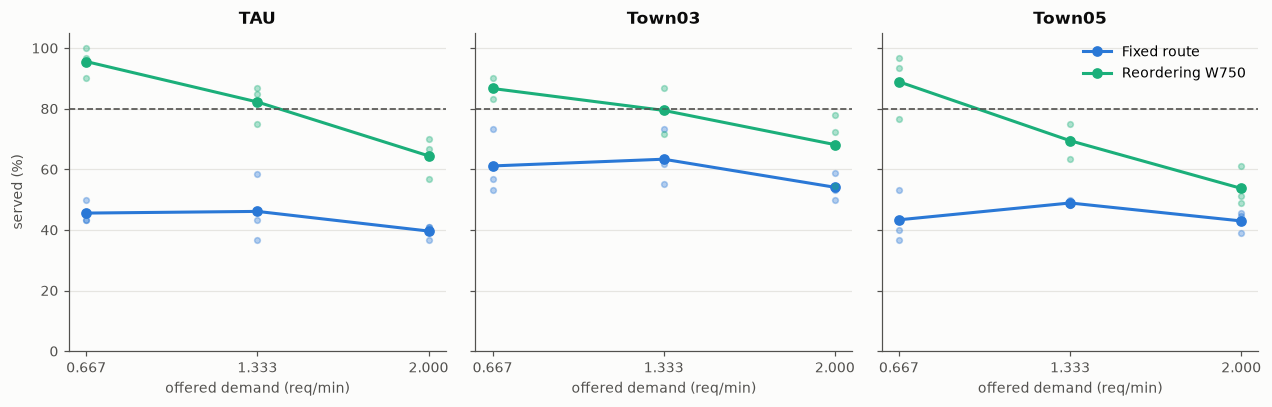

**Mean coverage (%)**

offered_per_min         0.666667  1.333333  2.000000
town   policy                                       
TAU    Fixed route          45.6      46.1      39.6
       Reordering W750      95.6      82.2      64.4
Town03 Fixed route          61.1      63.3      54.1
       Reordering W750      86.7      79.4      68.1
Town05 Fixed route          43.3      48.9      43.0
       Reordering W750      88.9      69.4      53.7

**Spread across the three seeds (std, points)** -- read every mean above against the cell beneath it.

offered_per_min         0.666667  1.333333  2.000000
town   policy                                       
TAU    Fixed route           3.8      11.1       2.6
       Reordering W750       5.1       6.3       6.9
Town03 Fixed route          10.7       9.3       4.5
       Reordering W750       3.3       7.5      12.2
Town05 Fixed route           8.8       1.0       3.6
       Reordering W750      10.7       5.9       6.5

In [8]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    towns = [t for t in ALL_TOWNS if t in set(frame["town"])]
    figure, axes = plt.subplots(
        1, len(towns), figsize=(3.9 * len(towns), 3.8), sharey=True,
        squeeze=False)
    for axis, town in zip(axes[0], towns):
        block = frame[frame["town"] == town]
        for label in POLICY_LABELS:
            arm = block[block["policy"] == label]
            series = arm.groupby("offered_per_min")["served"].mean(
                ).sort_index()
            if series.empty:
                continue
            axis.plot(series.index, series.values, marker="o", markersize=6,
                      lw=2.0, color=POLICY_COLOUR[label], label=label)
            # Every seed as a faint dot: three points behind each marker,
            # so a mean carried by one outlier is visible on the chart
            # rather than only in the table below.
            axis.scatter(arm["offered_per_min"], arm["served"], s=14,
                         alpha=0.35, color=POLICY_COLOUR[label], zorder=3)
        axis.axhline(GATE, ls="--", lw=1.1, color=INK_SOFT)
        axis.set_title(town)
        axis.set_xlabel("offered demand (req/min)")
        axis.set_xticks(sorted(frame["offered_per_min"].unique()))
        axis.set_ylim(0, 105)
        axis.grid(axis="y")
        axis.set_axisbelow(True)
    axes[0][0].set_ylabel("served (%)")
    axes[0][-1].legend()
    figure.tight_layout()
    plt.show()

    display(Markdown("**Mean coverage (%)**"))
    display(frame.pivot_table(index=["town", "policy"],
                              columns="offered_per_min",
                              values="served").round(1))
    display(Markdown("**Spread across the three seeds (std, points)** -- "
                     "read every mean above against the cell beneath it."))
    display(frame.pivot_table(index=["town", "policy"],
                              columns="offered_per_min", values="served",
                              aggfunc="std").round(1))

In [9]:
def breaking_point(runs: pd.DataFrame, gate: float = GATE) -> pd.DataFrame:
    """
    The fastest rung each (town, policy) still serves to the gate.

    Reported as a rung of the ladder rather than an interpolated crossing:
    at three seeds a rung the ladder is the honest resolution. The spread
    column is not decoration -- a verdict whose margin is inside it is a
    statement about the seeds, not about the load.

    :param runs: Collected runs.
    :param gate: Fulfilment percentage that counts as coping.
    :return: One row per town and policy.
    """
    if runs.empty:
        return pd.DataFrame()
    means = (runs.groupby(["town", "policy", "offered_per_min"])["served"]
             .agg(["mean", "std"]).reset_index())
    rows = []
    for (town, policy), group in means.groupby(["town", "policy"]):
        ladder = group.sort_values("offered_per_min")
        passing = ladder[ladder["mean"] >= gate]
        failing = ladder[ladder["mean"] < gate]
        if passing.empty:
            verdict = f"never -- fails from {ladder.iloc[0]['mean']:.0f}%"
            handled = float("nan")
        elif failing.empty:
            handled = passing["offered_per_min"].max()
            verdict = f"whole ladder to {handled:.2f}/min"
        else:
            handled = passing["offered_per_min"].max()
            first_fail = failing["offered_per_min"].min()
            verdict = (f"{handled:.2f}/min -- fails at {first_fail:.2f}"
                       if first_fail > handled
                       else f"non-monotonic; passes to {handled:.2f}/min")
        # How far the top rung sits from the gate, against its own spread.
        top = ladder.iloc[-1]
        margin = top["mean"] - gate
        spread = top["std"] if pd.notna(top["std"]) else float("nan")
        rows.append({
            "town": town, "policy": policy,
            "handled_per_min": handled,
            "easiest_rung_%": round(float(ladder.iloc[0]["mean"]), 1),
            "hardest_rung_%": round(float(top["mean"]), 1),
            "top_margin": round(float(margin), 1),
            "top_std": round(float(spread), 1),
            "decisive": "yes" if abs(margin) > spread else "inside noise",
            "verdict": verdict})
    return pd.DataFrame(rows).set_index(["town", "policy"])


if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    display(Markdown(f"**Breaking point** -- the fastest rung still served "
                     f"to the {GATE:.0f}% gate."))
    display(breaking_point(frame))
    display(Markdown(
        "`decisive` compares the top rung's distance from the gate against "
        "its own seed spread. **`inside noise` means the verdict beside it "
        "is not evidence** -- it is the same failure mode that produced the "
        "burst sweep's phantom breaking points, made visible instead of "
        "left to the reader."))

**Breaking point** -- the fastest rung still served to the 80% gate.

handled_per_min  easiest_rung_%  hardest_rung_%  \
town   policy                                                             
TAU    Fixed route                  NaN            45.6            39.6   
       Reordering W750         1.333333            95.6            64.4   
Town03 Fixed route                  NaN            61.1            54.1   
       Reordering W750         0.666667            86.7            68.1   
Town05 Fixed route                  NaN            43.3            43.0   
       Reordering W750         0.666667            88.9            53.7   

                        top_margin  top_std      decisive  \
town   policy                                               
TAU    Fixed route           -40.4      2.6           yes   
       Reordering W750       -15.6      6.9           yes   
Town03 Fixed route           -25.9      4.5           yes   
       Reordering W750       -11.9     12.2  inside noise   
Town05 Fixed route           -37.0      3.6           yes   
       Reordering W750       -26.3      6.5           yes   

                                          verdict  
town   policy                                      
TAU    Fixed route        never -- fails from 46%  
       Reordering W750  1.33/min -- fails at 2.00  
Town03 Fixed route        never -- fails from 61%  
       Reordering W750  0.67/min -- fails at 1.33  
Town05 Fixed route        never -- fails from 43%  
       Reordering W750  0.67/min -- fails at 1.33

`decisive` compares the top rung's distance from the gate against its own seed spread. **`inside noise` means the verdict beside it is not evidence** -- it is the same failure mode that produced the burst sweep's phantom breaking points, made visible instead of left to the reader.

## 6. Does the ranking invert?

The reason to run this notebook rather than extend the old one.

Every CARLA result so far ranks Reordering above fixed route, by 13–55
points, at every rate tried. But every one of them was measured under 36%
seat occupancy or less. The synthetic map says that ordering is **conditional
on occupancy**: below roughly 60% routing pays, above it the ranking inverts
and fixed route wins, because a full bus cannot honour the detours an
insertion policy plans.

The left panel is the usual advantage-against-rate view. **The right panel is
the actual test**: the same advantage plotted against measured occupancy, with
the 60% line drawn. If the CARLA points cross zero near that line, the
synthetic scope condition transfers to real geometry and it belongs in the
recommendation. If they stay positive well past it, the scope condition is a
property of the synthetic map and the recommendation is simpler than we
thought.

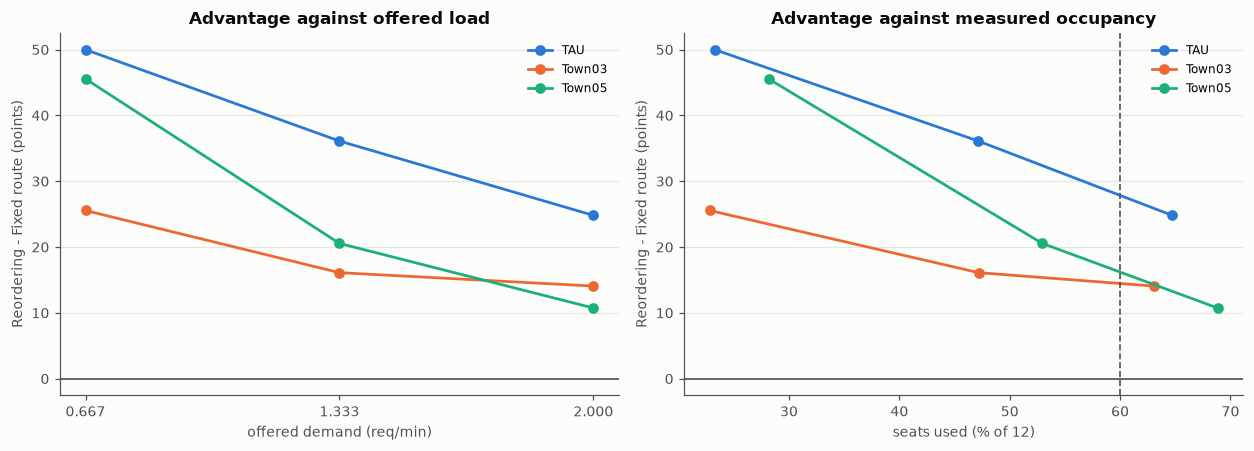

**Reordering W750 - Fixed route, in points of coverage**, per rung.

offered_per_min,0.666667,1.333333,2.000000
TAU,50.0,36.1,24.8
Town03,25.6,16.1,14.1
Town05,45.6,20.6,10.7


> **No inversion anywhere on this ladder.** Reordering leads at every rung in every town. Read this against the peak occupancy printed in section 4: it only rules the inversion out up to the occupancy actually reached.

In [10]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    guard = saturation(frame)
    towns = [t for t in ALL_TOWNS if t in set(frame["town"])]

    figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    gaps = {}
    for town in towns:
        block = frame[frame["town"] == town]
        best = (block[block["policy"] == "Reordering W750"]
                .groupby("offered_per_min")["served"].mean())
        base = (block[block["policy"] == "Fixed route"]
                .groupby("offered_per_min")["served"].mean())
        shared = sorted(set(best.index) & set(base.index))
        if not shared:
            continue
        advantage = (best - base).loc[shared]
        gaps[town] = advantage
        axes[0].plot(shared, advantage.values, marker="o", markersize=6,
                     lw=1.8, label=town)

        # Occupancy of the busier of the two arms at each rung: the
        # inversion is about how full the bus is, and pairing the advantage
        # with the mean of both arms would blur a difference that is itself
        # part of the story.
        occupancy = (guard[guard["town"] == town]
                     .groupby("offered_per_min")["seats_used"].max()
                     .loc[shared])
        axes[1].plot(occupancy.values, advantage.values, marker="o",
                     markersize=6, lw=1.8, label=town)

    axes[0].axhline(0, lw=1.1, color=INK_SOFT)
    axes[0].set_title("Advantage against offered load")
    axes[0].set_xlabel("offered demand (req/min)")
    axes[0].set_ylabel("Reordering - Fixed route (points)")
    axes[0].set_xticks(sorted(frame["offered_per_min"].unique()))
    axes[0].grid(axis="y")
    axes[0].set_axisbelow(True)
    axes[0].legend(fontsize=8)

    axes[1].axhline(0, lw=1.1, color=INK_SOFT)
    axes[1].axvline(INVERSION_OCCUPANCY, ls="--", lw=1.1, color=INK_SOFT)
    axes[1].set_title("Advantage against measured occupancy")
    axes[1].set_xlabel(f"seats used (% of {CAPACITY})")
    axes[1].set_ylabel("Reordering - Fixed route (points)")
    axes[1].grid(axis="y")
    axes[1].set_axisbelow(True)
    axes[1].legend(fontsize=8)
    figure.tight_layout()
    plt.show()

    display(Markdown("**Reordering W750 - Fixed route, in points of "
                     "coverage**, per rung."))
    display(pd.DataFrame(gaps).T.round(1))

    crossed = {t: g for t, g in gaps.items() if (g < 0).any()}
    if crossed:
        display(Markdown(
            "> **The ranking inverts in "
            f"{', '.join(sorted(crossed))}.** Check the seed spread in "
            "section 5 for those cells before believing it, then report the "
            "occupancy it happened at, not the rate."))
    else:
        display(Markdown(
            "> **No inversion anywhere on this ladder.** Reordering leads "
            "at every rung in every town. Read this against the peak "
            "occupancy printed in section 4: it only rules the inversion "
            "out up to the occupancy actually reached."))

## 7. Sustained against burst, rung for rung

The two experiments offer the same three rates to the same three towns. The
only difference is whether the volume scaled with the rate.

**This section only means anything at the burst sweep's own capacity.** The
`BURST` figures below were measured at 20 seats, so a notebook running any
other capacity would be differencing two variables at once and reporting the
result as if it were volume alone. When the capacities do not match the
comparison is skipped rather than shown with a caveat, because the table is
the sort that gets quoted away from its warning.

**At a matching capacity the 0.67/min rung is literally the same runs in
both**, so its columns must agree exactly. They are printed as a check: a
discrepancy there means one of the two store filters is admitting something
it should not, and nothing else in this notebook can be trusted until it is
explained.

Above that rung, the burst sweep offered 30 requests and this one offers 60
and 90. The gap between the two curves at a given rate is therefore the price
of *volume*, holding rate fixed — which is the quantity neither notebook
could isolate on its own.

In [ ]:
# Measured in carla-demand-sweep.ipynb: mean coverage (%) at 30 requests,
# three seeds, capacity 20, patience 750 s. Burst, not sustained -- the
# arrival span shrank with the interval, so 2.00/min there was 30 requests
# in 900 s followed by quiet.
#
# The seat count these were measured at. Transcribed numbers cannot be
# re-filtered the way the store can, so this is the one thing about them
# that has to be stated rather than looked up.
BURST_CAPACITY = 20
BURST = {
    ("TAU", "Fixed route"): {0.67: 47.8, 1.33: 41.1, 2.00: 64.4},
    ("TAU", "Reordering W750"): {0.67: 94.4, 1.33: 86.7, 2.00: 88.9},
    ("Town03", "Fixed route"): {0.67: 63.3, 1.33: 70.0, 2.00: 56.7},
    ("Town03", "Reordering W750"): {0.67: 90.0, 1.33: 86.7, 2.00: 84.4},
    ("Town05", "Fixed route"): {0.67: 43.3, 1.33: 47.8, 2.00: 55.6},
    ("Town05", "Reordering W750"): {0.67: 88.9, 1.33: 72.2, 2.00: 70.0},
}

if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
elif CAPACITY != BURST_CAPACITY:
    # Not a failure -- the burst sweep was simply never run at this
    # capacity. Differencing across both would price volume and seats
    # together and label the total "volume_cost".
    display(Markdown(
        f"> **Skipped: no burst sweep at {CAPACITY} seats.** The `BURST` "
        f"figures above were measured at {BURST_CAPACITY}, so every "
        "difference here would carry a capacity change as well as a volume "
        "change, including at the anchor rung. Run "
        "`carla-demand-sweep.ipynb` at this capacity, or read section 7 in "
        f"the {BURST_CAPACITY}-seat notebook instead."))
else:
    sustained = frame.pivot_table(index=["town", "policy"],
                                  columns="offered_per_min", values="served")
    rows = []
    for (town, policy), burst in BURST.items():
        if (town, policy) not in sustained.index:
            continue
        here = sustained.loc[(town, policy)]
        for rate, burst_value in sorted(burst.items()):
            match = [c for c in here.index if abs(c - rate) < 0.01]
            if not match:
                continue
            rows.append({"town": town, "policy": policy, "rate": rate,
                         "burst": burst_value,
                         "sustained": round(float(here[match[0]]), 1)})
    comparison = pd.DataFrame(rows)
    comparison["volume_cost"] = (comparison["sustained"]
                                 - comparison["burst"]).round(1)

    anchor_rate = 60.0 / ANCHOR_INTERVAL
    anchor = comparison[comparison["rate"].sub(anchor_rate).abs() < 0.01]
    drift = anchor["volume_cost"].abs().max() if not anchor.empty else 0.0
    if drift < 0.05:
        display(Markdown(
            f"> **Anchor check passed.** At {anchor_rate:.2f}/min the two "
            "notebooks agree to the decimal, as they must -- they are "
            "reading the same runs."))
    else:
        display(Markdown(
            f"> **Anchor check FAILED by {drift:.1f} points.** The "
            f"{anchor_rate:.2f}/min rung should be identical in both "
            "notebooks. Stop and reconcile the store filters before "
            "reading anything below."))

    display(Markdown("**Coverage (%), burst vs sustained.** `volume_cost` "
                     "is sustained minus burst: what the extra riders cost "
                     "at the same arrival rate."))
    display(comparison.set_index(["town", "policy", "rate"]))

    figure, axes = plt.subplots(
        1, len(ALL_TOWNS), figsize=(3.9 * len(ALL_TOWNS), 3.6), sharey=True,
        squeeze=False)
    for axis, town in zip(axes[0], ALL_TOWNS):
        block = comparison[comparison["town"] == town]
        for label in POLICY_LABELS:
            arm = block[block["policy"] == label].sort_values("rate")
            if arm.empty:
                continue
            axis.plot(arm["rate"], arm["sustained"], marker="o",
                      markersize=6, lw=2.0, color=POLICY_COLOUR[label],
                      label=f"{label} (sustained)")
            axis.plot(arm["rate"], arm["burst"], marker="s", markersize=5,
                      lw=1.4, ls=":", color=POLICY_COLOUR[label],
                      label=f"{label} (burst)")
        axis.axhline(GATE, ls="--", lw=1.1, color=INK_SOFT)
        axis.set_title(town)
        axis.set_xlabel("offered demand (req/min)")
        axis.set_xticks(sorted(comparison["rate"].unique()))
        axis.set_ylim(0, 105)
        axis.grid(axis="y")
        axis.set_axisbelow(True)
    axes[0][0].set_ylabel("served (%)")
    axes[0][-1].legend(fontsize=7)
    figure.tight_layout()
    plt.show()

## 8. Health

CARLA failures are not rare enough to ignore. A run with repaths was
physically stuck at some point; a run with unroutable legs asked for a leg
`plan_route` could not build. Neither invalidates a run on its own, but a
rung whose coverage collapses *and* whose repath count jumps is a driving
failure wearing a demand failure's clothes.

In the burst sweep every flagged run was Town02 or Town01 and the towns that
actually failed the gate had none, so the failures there were routing, not
driving. The busier rungs here put the bus on the road for longer at a time,
so that is worth re-checking rather than assuming.

In [12]:
if not HAVE_RUNS:
    display(Markdown("_Nothing to report until the sweep has run._"))
else:
    health = frame.groupby(["town", "offered_per_min"]).agg(
        runs=("repaths", "size"), repaths=("repaths", "sum"),
        unroutable=("unroutable", "sum"),
        stuck_runs=("repaths", lambda c: int((c > 0).sum())))
    display(Markdown("**Per town and rung.** `stuck_runs` is the count of "
                     "runs with at least one repath."))
    display(health)

    suspect = frame[(frame["repaths"] > 0) | (frame["unroutable"] > 0)]
    print(f"{len(suspect)} of {len(frame)} runs carry a repath or an "
          f"unroutable leg")
    if not suspect.empty:
        display(suspect.groupby(["town", "policy", "offered_per_min"])[
            ["repaths", "unroutable", "served"]].mean().round(1))

    # The question health is actually being asked: do the runs that failed
    # the gate look different from the ones that passed?
    frame["passed_gate"] = frame["served"] >= GATE
    display(Markdown("**Failures against the gate.** If the failing runs "
                     "carry no more repaths than the passing ones, the "
                     "coverage shortfall is routing rather than driving."))
    display(frame.groupby("passed_gate")[
        ["repaths", "unroutable", "served", "sim_s"]].mean().round(1))

**Per town and rung.** `stuck_runs` is the count of runs with at least one repath.

runs  repaths  unroutable  stuck_runs
town   offered_per_min                                       
TAU    0.666667            6        0           0           0
       1.333333            6        0           0           0
       2.000000            6        0           0           0
Town03 0.666667            6        0           0           0
       1.333333            6        0           0           0
       2.000000            6        0           0           0
Town05 0.666667            6        0           0           0
       1.333333            6        1           0           1
       2.000000            6        0           0           0

1 of 54 runs carry a repath or an unroutable leg


,,,repaths,unroutable,served
town,policy,offered_per_min,,,
Town05,Reordering W750,1.333333,1.0,0.0,70.0


**Failures against the gate.** If the failing runs carry no more repaths than the passing ones, the coverage shortfall is routing rather than driving.

,repaths,unroutable,served,sim_s
passed_gate,,,,
False,0.0,0.0,55.4,3920.3
True,0.0,0.0,89.6,3506.3
